# Projet Leyenda - Livrable 1

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:
![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Dans ce ***premier livrable***, nous créeons un CNN via la bibliothéque tensorFlow, pour cela nous utilisons un dataset que nous importons et effectuant un pré traitement, en créeant des dossiers dans le dossier mère : *process* True et False, permettant de regroupé les groupes d'images pour ensuite les splité en différents sets : Train, Test et Valid. 

Détail du ***Livrable 1:***
- Le code TensorFlow ainsi qu'un schéma de l'architecture du réseau de neurones. Toutes les parties doivent être détaillée dans le notebook : les paramètre du réseau, la fonction de perte ainsi que l'algorithme d'optimisation utilisé pour l’entraînement.
- Un graphique contenant l'évolution de l'erreur d’entraînement ainsi que de l'erreur de test et l'évolution de l'accuracy pour ces deux datasets.
- L'analyse de ces résultats, notamment le compromis entre biais et variance (ou sur-apprentissage et sous-apprentissage).
- Une description des méthodes potentiellement utilisables pour améliorer les compromis biais/variance : technique de régularisation, drop out, early-stopping, ...

***Pour le CNN , nous créeons l'architecture suivante:***
- Importation du dataset et la division en 75%/15%/10%
- La normalisation des données /255 pour que les valeurs soit comprise entre 0.0 et 1.0
- Nous initialiation le modèle avec plusieurs couches de Convulation (conv2d) et pooling (Maxpooling2D)
- Nous transformons ensuite l'image en un vecteur de une dimension avec Flatten
- Pour finir avec les dense Layers et une sortie binaire avec la formule mathématique utilisé ici sigmoid


# Etape 1:
### Schéma de notre architecture :

### Importation des librairies

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from DL_dataset import *

### Les paramètres et hyperparametres utilisé:
- Epoch :
- $\lambda$ :
- learning rate :
- BATCH_SIZE : 
- Dropout :
- Patience :
- Train et Test split:
- img_size:

In [5]:
Epoch=10
lambda_l2=0.001
learning_rate=0.01
BATCH_SIZE=32
Dropout:0.1
Patience=5
train_split=0.75
test_split=0.25
img_size=64

### Téléchargement et préprocessing des données
Chaque step peut etre activé ou non, la première est le téléchargement des fichiers zip, la deuxieme étape est de dézipé les fichiers et la dernière est de fusionner les datasets dans le dossier processing avec un sous dossier True pour les photo et les autres Dataset dans False.

In [3]:
step_DL=True      
step_unzip=True
step_process=True

urls=[
    "https://drive.google.com/file/d/1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX/view?usp=sharing",
    "https://drive.google.com/file/d/1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy/view?usp=sharing",
    "https://drive.google.com/file/d/1J-WupkQTuwmniUiO-E0rMQzsl2Pi1J5o/view?usp=sharing",
    "https://drive.google.com/file/d/1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_/view?usp=sharing",
    "https://drive.google.com/file/d/16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T/view?usp=sharing"
]

folder_raw = Path(f"./data/raw")
folder_process = Path(f"./data/processing")

if not os.path.exists(folder_raw):
    os.makedirs(folder_raw)

if not os.path.exists(folder_process):
    os.makedirs(folder_process)

if step_DL==True:
    print("File download:")
    for link in urls:
        download_file(link,folder_raw)

if step_unzip==True:
    Get_file(folder_raw)

if step_process==True:
    file_list=copy(folder_process)
    Check_corruption(folder_process)

File download:


Downloading...
From (original): https://drive.google.com/uc?id=1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX
From (redirected): https://drive.google.com/uc?id=1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX&confirm=t&uuid=f98af8d2-26c4-4fbd-9e9e-f1d0f685b807
To: c:\Users\hmjhl\Documents\GitHub\Cnn-and-RNN\data\raw\downloaded_file1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX.zip
100%|██████████| 4.61G/4.61G [03:12<00:00, 23.9MB/s]


Donwload complete


Downloading...
From (original): https://drive.google.com/uc?id=1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy
From (redirected): https://drive.google.com/uc?id=1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy&confirm=t&uuid=1e013dc0-890c-450d-8d3c-ff9660e4dfed
To: c:\Users\hmjhl\Documents\GitHub\Cnn-and-RNN\data\raw\downloaded_file1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy.zip
100%|██████████| 1.62G/1.62G [01:08<00:00, 23.5MB/s]


Donwload complete


...

Donwload complete


Downloading...
From (original): https://drive.google.com/uc?id=1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_
From (redirected): https://drive.google.com/uc?id=1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_&confirm=t&uuid=3f2374a0-95bd-4523-bedf-03e9a1232f76
To: c:\Users\hmjhl\Documents\GitHub\Cnn-and-RNN\data\raw\downloaded_file1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_.zip
100%|██████████| 47.5M/47.5M [00:02<00:00, 23.6MB/s]


Donwload complete


Downloading...
From (original): https://drive.google.com/uc?id=16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T
From (redirected): https://drive.google.com/uc?id=16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T&confirm=t&uuid=e49756c1-b0e5-461c-b853-e20b499fbf59
To: c:\Users\hmjhl\Documents\GitHub\Cnn-and-RNN\data\raw\downloaded_file16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T.zip
100%|██████████| 663M/663M [00:39<00:00, 16.8MB/s] 


Donwload complete
File extract for data\raw\downloaded_file16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T.zip
File extract for data\raw\downloaded_file1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX.zip
File extract for data\raw\downloaded_file1J-WupkQTuwmniUiO-E0rMQzsl2Pi1J5o.zip
File extract for data\raw\downloaded_file1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_.zip
File extract for data\raw\downloaded_file1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy.zip
Painting to data\processing\False
Photo to data\processing\True
Schematics to data\processing\False
Sketch to data\processing\False
Text to data\processing\False
Corrupted image detected and deleted: data\processing\False\Painting_painting_02662.jpg
Corrupted image detected and deleted: data\processing\False\Schematics_desktop.ini


### Division des datasets en un dataset Train et False

In [6]:
dossier_racine = Path(f"./data/processing/")
train_set = tf.keras.preprocessing.image_dataset_from_directory(
  dossier_racine,
  validation_split= 1-train_split,
  subset =  "training",
  seed=42,
  batch_size=BATCH_SIZE,
  image_size=(img_size,img_size)
)

test_set = tf.keras.preprocessing.image_dataset_from_directory(
  dossier_racine,
  validation_split= test_split,
  subset =  "validation",
  seed=42,
  batch_size=BATCH_SIZE,
  image_size=(img_size,img_size),
)

AUTOTUNE = tf.data.experimental.AUTOTUNE

train_set = train_set.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Found 41398 files belonging to 2 classes.
Using 31049 files for training.
Found 41398 files belonging to 2 classes.
Using 10349 files for validation.


### Création de l'architecture du modèle

In [ ]:
model_layers = [
    keras.Input(shape=(None, None, 3)), 
    
    # Redimensionnement 
    layers.Resizing(img_size, img_size),

    #Normalisation
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
]

if img_size == 256: 
    model_layers.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
    ])

model_layers.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model = keras.Sequential(model_layers)

### Choix de la métrique et de l'optimizer
On utilise un optimiser pour mettre à jour les poids en utilisant la descente de gradient lors de la backpropagation, le plus souvent on utilise l'agorithme Adam qui mets à jour automatiquement le Learning rate pour chaque poids en améliorant la vitesse et les performances d'entrainement. Lorsqu'on compile le modèle avec TensorFlow, on choisit la métrique que l'on peut observé, ici l'accuracy de notre modèle. La loss fonction est utilisé pour calculé la différence entre les prédictions de notre modèle et les véritables images. Plusieurs méthodes sont disponible pour le CNN:

- Binary Cross-Entropy (Pour la classification binaire)
- Categorical Cross-Entropy (Pour la classification de plusieurs classes)
- Sparse Categorical Crossentropy (Pour la classification de plusieurs classes, mais les labels sont des numéros entier 1,2 etc...)

On va donc utiliser ici la ***Binary Cross-Entropy***.

In [14]:
model.compile(optimizer ="adam",  #A COMPLETER
              loss =  "binary_crossentropy",
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,281 (6.20 MB)

 Trainable params: 1,625,281 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

### Lancement du modèle
Avec la fonction ***Model.fit*** va permettre de lancer l'entrainement avec différents paramètres tels que le nombre d'epochs, est le nombre de fois que le modèle s'entraine, ***validation_data*** est quant à lui, la partie avec lequel la data sera testé, ici le dataset défini plus haut *test_set*.

In [15]:
history = model.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.8286 - loss: 0.3406 - val_accuracy: 0.8700 - val_loss: 0.2812
Epoch 2/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.8785 - loss: 0.2645 - val_accuracy: 0.8968 - val_loss: 0.2413
Epoch 3/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9032 - loss: 0.2221 - val_accuracy: 0.9034 - val_loss: 0.2245
Epoch 4/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9236 - loss: 0.1799 - val_accuracy: 0.9100 - val_loss: 0.2150
Epoch 5/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9435 - loss: 0.1393 - val_accuracy: 0.9091 - val_loss: 0.2342
Epoch 6/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9602 - loss: 0.1015 - val_accuracy: 0.9108 - val_loss: 0.2568
Epoch 7/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9725 - loss: 0.0712 - val_accuracy: 0.9097 - val_loss: 0.2943
Epoch 8/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9831 - loss: 0.0468 - 

# Etape 2:
### Graphique des résultats obtenu pour le modèle:
Dans ce graphique, nous regardons l'accuracy et la fonction de perte dans ce graphique au cours de l'entrainement à chaque epoch.

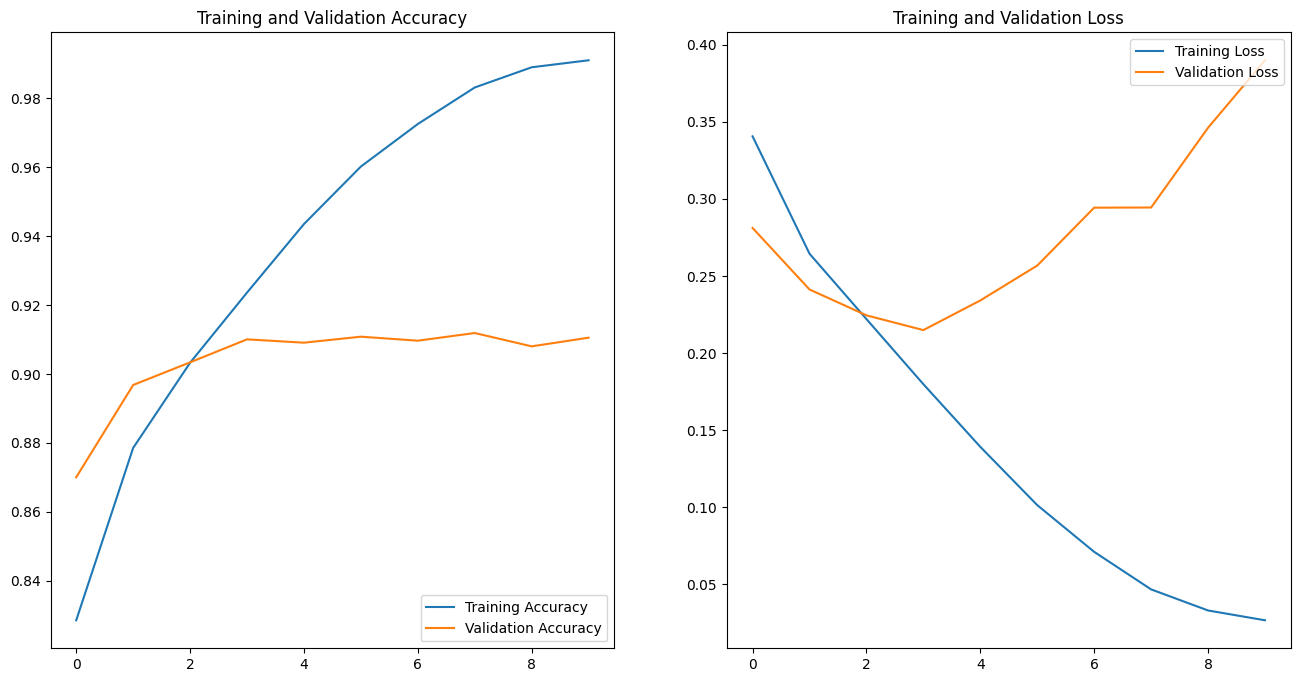

In [16]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(Epoch)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

***Résultat:*** En observant les deux graphs obtenus, on remarque une grosse différence dans la fonction de perte entre celui de Train et celui de validation, ce qui indique une grande variance donc un overfitting, pour résoudre ce problème, nous utiliserons différents paramètres à notre disposition pour pouvoir régler cet overfitting tout en évitant l'under-fitting.

# Etape3
### Modèle avec les différentes méthodes contre l'over et l'underfitting

Code NoahV (DataAugmentation il me semble)

In [7]:
model_layers = [
    keras.Input(shape=(None, None, 3)), 
    
    # Redimensionnement 
    layers.Resizing(img_size, img_size),

    # Normalisation
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.2), 
]

if img_size == 256: 
    model_layers.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
    ])

model_layers.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2), 
    layers.Dense(1, activation='sigmoid')
])

model_dropout = keras.Sequential(model_layers)

model_dropout.compile(optimizer="adam", 
              loss="binary_crossentropy",
              metrics=['accuracy'])

In [8]:
history_dropout = model_dropout.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 61s 39ms/step - accuracy: 0.8169 - loss: 0.3507 - val_accuracy: 0.8645 - val_loss: 0.2875
Epoch 2/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.8631 - loss: 0.2873 - val_accuracy: 0.8909 - val_loss: 0.2544
Epoch 3/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - accuracy: 0.8903 - loss: 0.2476 - val_accuracy: 0.8740 - val_loss: 0.2630
Epoch 4/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 25s 26ms/step - accuracy: 0.9057 - loss: 0.2205 - val_accuracy: 0.9058 - val_loss: 0.2171
Epoch 5/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 25s 25ms/step - accuracy: 0.9183 - loss: 0.1963 - val_accuracy: 0.9133 - val_loss: 0.2047
Epoch 6/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.9290 - loss: 0.1734 - val_accuracy: 0.9139 - val_loss: 0.2138
Epoch 7/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 32s 33ms/step - accuracy: 0.9397 - loss: 0.1493 - val_accuracy: 0.8810 - val_loss: 0.2714
Epoch 8/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.9519 - loss: 0.1233 - 

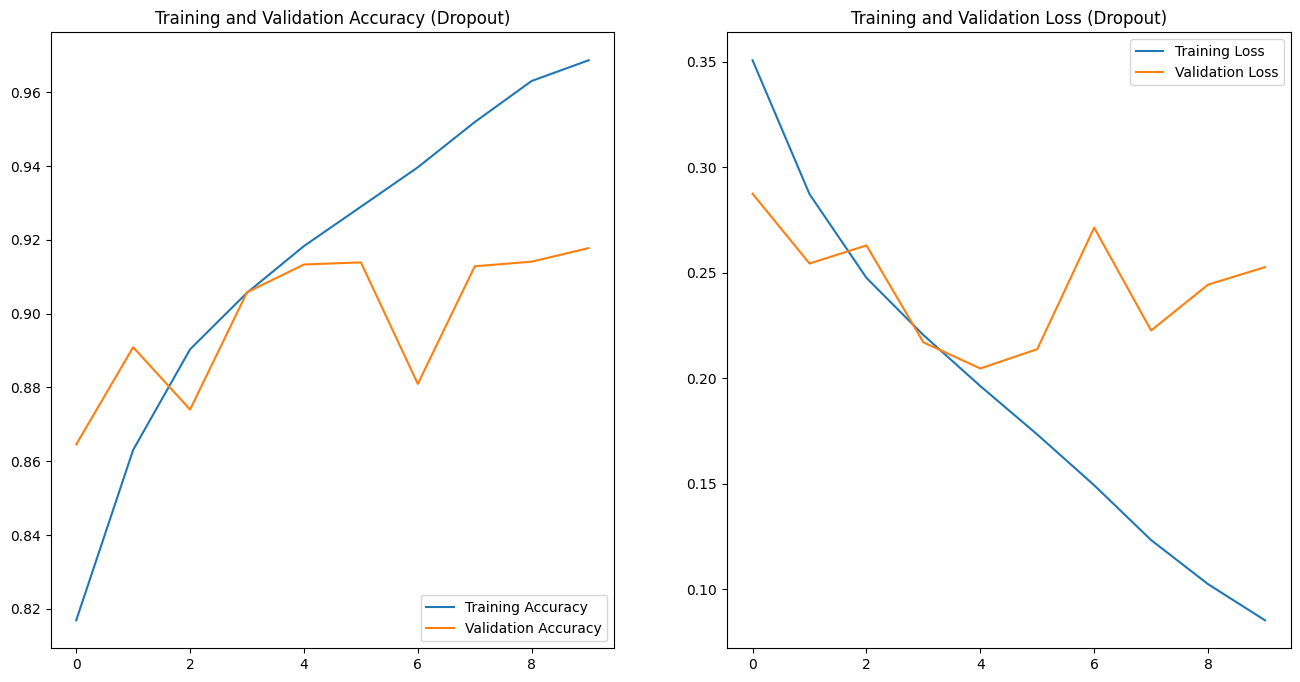

In [9]:
acc = history_dropout.history['accuracy']
val_acc = history_dropout.history['val_accuracy']

loss = history_dropout.history['loss']
val_loss = history_dropout.history['val_loss']

epochs_range = range(Epoch)



plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy (Dropout)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss (Dropout)')
plt.show()

In [10]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

model_layers_final = [
    keras.Input(shape=(None, None, 3)), 
    
    layers.Resizing(img_size, img_size),
    
    data_augmentation, 
    
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
]

if img_size == 256: 
    model_layers_final.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
    ])

model_layers_final.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.1), 
    layers.Dense(1, activation='sigmoid')
])

model_final = keras.Sequential(model_layers_final)

model_final.compile(optimizer="adam", 
              loss="binary_crossentropy",
              metrics=['accuracy'])

In [11]:
history_final = model_final.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 32s 31ms/step - accuracy: 0.8226 - loss: 0.3457 - val_accuracy: 0.7991 - val_loss: 0.3969
Epoch 2/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8613 - loss: 0.2933 - val_accuracy: 0.8399 - val_loss: 0.3122
Epoch 3/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8805 - loss: 0.2670 - val_accuracy: 0.8765 - val_loss: 0.2615
Epoch 4/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8893 - loss: 0.2499 - val_accuracy: 0.8840 - val_loss: 0.2579
Epoch 5/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8938 - loss: 0.2388 - val_accuracy: 0.8894 - val_loss: 0.2420
Epoch 6/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - accuracy: 0.9006 - loss: 0.2286 - val_accuracy: 0.8947 - val_loss: 0.2317
Epoch 7/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.9038 - loss: 0.2212 - val_accuracy: 0.8728 - val_loss: 0.3165
Epoch 8/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 27s 27ms/step - accuracy: 0.9082 - loss: 0.2104 - 

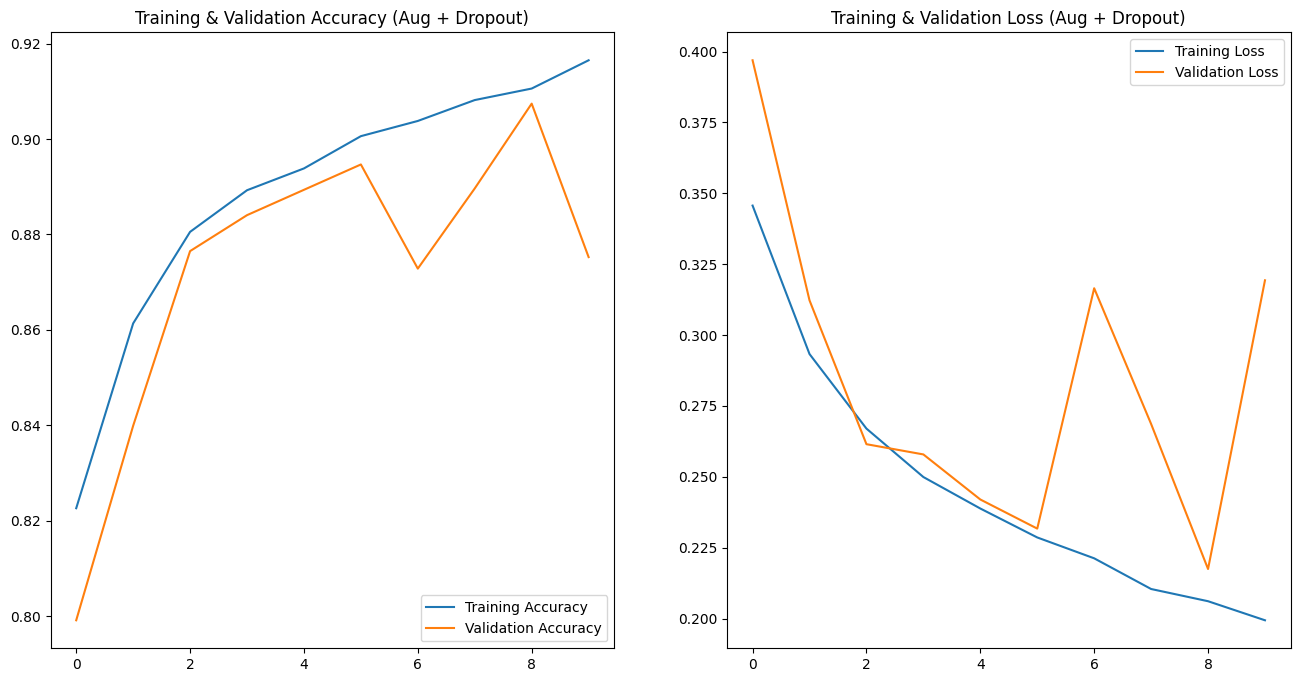

In [12]:
acc_final = history_final.history['accuracy']
val_acc_final = history_final.history['val_accuracy']

loss_final = history_final.history['loss']
val_loss_final = history_final.history['val_loss']

epochs_range = range(Epoch)



plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_final, label='Training Accuracy')
plt.plot(epochs_range, val_acc_final, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy (Aug + Dropout)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_final, label='Training Loss')
plt.plot(epochs_range, val_loss_final, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss (Aug + Dropout)')
plt.show()

### Code avec les différentes méthodes dropout, l2 régularization, callbacks...

In [19]:
"""
Add callback
"""
early_stopping_callback = EarlyStopping(
monitor='val_loss', # The metric to monitor for improvement
patience=Patience,         # Number of epochs with no improvement after which training will be stopped
verbose=1,          # Show a message when stopping
restore_best_weights=True # Restores model weights from the epoch with the best value of the monitored quantity.
)

"""
Load and configure model
"""

model_layers_total = [
    keras.Input(shape=(None, None, 3)), 
    
    # Redimensionnement 
    layers.Resizing(img_size, img_size),

    #data augmentation
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),

    #Scale to 0 to 1
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.1),
]

if img_size == 256: 
    model_layers_total.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.1),
    ])

model_layers_total.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(lambda_l2)),
    layers.Dense(1, activation='sigmoid', kernel_regularizer=regularizers.l2(lambda_l2))
])

model_total = keras.Sequential(model_layers_total)
print(model_total.summary())

"""
Configure Optimizer
"""
model_total.compile(optimizer='adam',
            loss='binary_crossentropy',
            metrics=['accuracy'])

"""
Launch model
"""
all_callbacks = [early_stopping_callback]
print(f"Lancement du train du modele pour {img_size}x{img_size}")
history_model = model_total.fit(
    train_set, 
    epochs=Epoch, 
    callbacks=all_callbacks, 
    validation_data=test_set
)

"""
Save mode
"""
os.makedirs("Model", exist_ok=True)
final_accuracy = round(history_model.history['accuracy'][-1], 4)
final_loss = round(history_model.history['loss'][-1], 4)

model_total.save(f"Model/Modele_cnn_{img_size}x{img_size}_{final_accuracy}accuracy_{final_loss}loss.keras")

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_7 (Resizing)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_6 (RandomFlip)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_6               │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_7 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,281 (6.20 MB)

 Trainable params: 1,625,281 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

None
Lancement du train du modele pour 64x64
Epoch 1/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 29s 29ms/step - accuracy: 0.8062 - loss: 0.3971 - val_accuracy: 0.8431 - val_loss: 0.3451
Epoch 2/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 29s 29ms/step - accuracy: 0.8440 - loss: 0.3438 - val_accuracy: 0.8518 - val_loss: 0.3297
Epoch 3/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - accuracy: 0.8605 - loss: 0.3242 - val_accuracy: 0.8491 - val_loss: 0.3323
Epoch 4/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - accuracy: 0.8669 - loss: 0.3104 - val_accuracy: 0.8714 - val_loss: 0.3028
Epoch 5/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - accuracy: 0.8714 - loss: 0.3053 - val_accuracy: 0.8699 - val_loss: 0.3128
Epoch 6/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - accuracy: 0.8732 - loss: 0.2961 - val_accuracy: 0.8637 - val_loss: 0.3083
Epoch 7/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - accuracy: 0.8791 - loss: 0.2915 - val_accuracy: 0.8804 - val_loss: 0.2872
Epoch 8/10
971/971 ━━━━━━━━━━━━━━━━━━━━ 28s 2

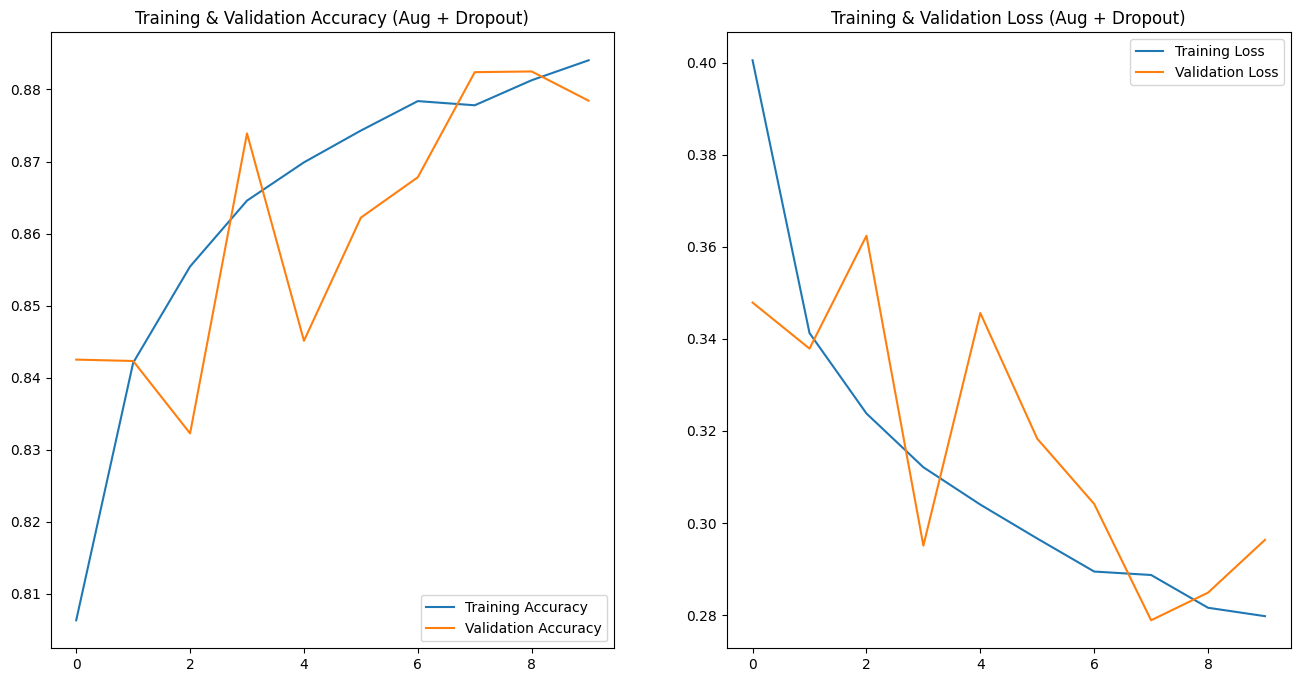

In [16]:
acc_final = history_model.history['accuracy']
val_acc_final = history_model.history['val_accuracy']

loss_final = history_model.history['loss']
val_loss_final = history_model.history['val_loss']

epochs_range = range(Epoch)



plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_final, label='Training Accuracy')
plt.plot(epochs_range, val_acc_final, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy (Aug + Dropout)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_final, label='Training Loss')
plt.plot(epochs_range, val_loss_final, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss (Aug + Dropout)')
plt.show()

### Comparaison entre les différents modèles avec différents paramètres:

Code hugo

In [ ]:
import pandas as pd
folder_model = Path(f"./data/model")

model_name=[]

#chargement de tout les modèles sauvegardé avec les différents test éffectués
for path in folder_model.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".keras", ".h5", ".hdf5"
    }:
        model_name.append(path)

result=[]
for model_x in model_name:
    print(f"Évaluation : {model_x.name}")
    model_y = tf.keras.models.load_model(model_x)

    loss, accuracy = model_y.evaluate(X_test,y_test,verbose=0) #crée un split validation par exemple de 5%, change model par le nom du modèle de notre architecture

    result.append({
        "model": model_x.name,
        "loss": loss,
        "accuracy": accuracy
    }) 

df = pd.DataFrame(result)

df.plot(kind="bar", x="model", y="accuracy", color="teal", legend=False)

# Add title and labels
plt.title("Accuracy for each Model")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.show()

df.plot(kind="bar", x="model", y="loss", color="teal", legend=False)

# Add title and labels
plt.title("Loss for each Model")
plt.xlabel("Model")
plt.ylabel("Loss")
plt.show()

# Etape 4
Pour faire face à l'under-fitting et d'over-fitting, nous avons utilisé plusieurs principes très connu et disponible sur tensorflow comme ***Dropout***, qui va nous servir pour contrer l'over-fitting en désactivent certains neurones, nous avons testés plusieurs valeurs comme 0.1, 0.2 et 0.4. Les deux meilleurs résultats ont été avec 0.1 et 0.2. Comme autre méthodes, nous avons rajouté dans les dense layer, ***un l2_regularization*** Va appliqué une pénalité sur les poids trop grand, cela force pendant l'optimisation des poids se rapproche de 0, la valeur pour définir la puissance de cette pénalité est choisit via l'hyperparamètres **lambda ($\lambda$**) la puissance de cette pénalité. La dernière technique est le ***Early stopping Callback***, on l'utilise pour stopper l'entrainement du modèle quand la valeur cible ne s'améliore pas, on défini un hyperparamètre patience qui s'y active après x fois défini est atteinte et que pendant cette période il y a eu aucune amélioration et limité l'overfitting car le modèle est devenu "paraisseux".
Pour l'under-fitting, nous jouons avec les différents hyperparametres et faisons aussi la data augmentation qui permet d'avoir dans le train set un nombre similaire de True et False, pour que son entrainement soit claire et détaillé.